# deskripsi library yang digunakan

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Memanggil Dataset

In [11]:
df = pd.read_csv('toyota.csv')

# Deskripsi Dataset

In [12]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   str    
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   str    
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   str    
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 473.9 KB


<Axes: >

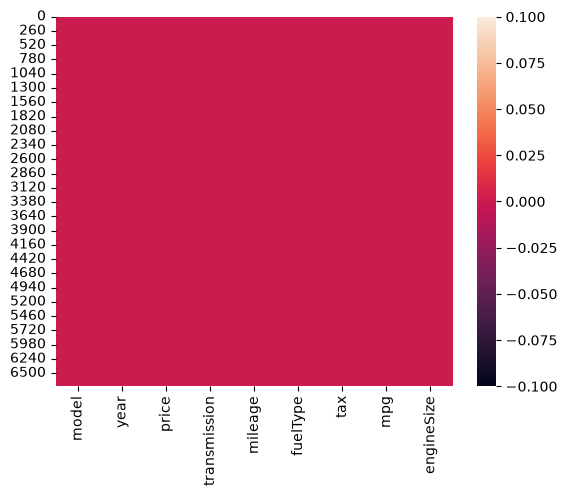

In [14]:
sns.heatmap(df.isnull())

In [15]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000
mean,2016.748145,12522.391066,22857.413921,94.697240,63.042223,1.471297
std,2.204062,6345.017587,19125.464147,73.880776,15.836710,0.436159
min,1998.000000,850.000000,2.000000,0.000000,2.800000,0.000000
25%,2016.000000,8290.000000,9446.000000,0.000000,55.400000,1.000000
50%,2017.000000,10795.000000,18513.000000,135.000000,62.800000,1.500000
75%,2018.000000,14995.000000,31063.750000,145.000000,69.000000,1.800000
max,2020.000000,59995.000000,174419.000000,565.000000,235.000000,4.500000


# Visualisasi Data

<Axes: >

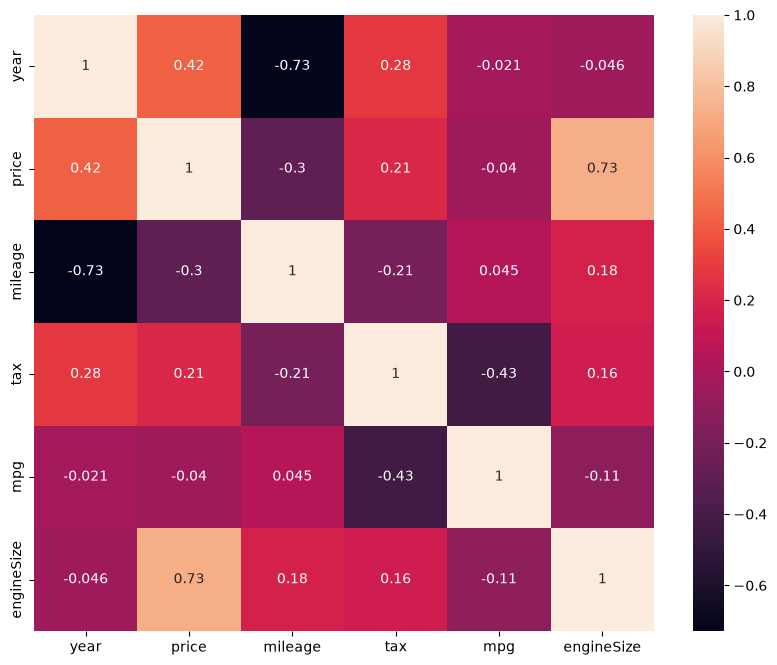

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Jumlah mobil berdasarkan model


In [ ]:
models = df.groupby('model').count()[['tax']].reset_index()
models = models.rename(columns={'tax': 'numberOfCars'})

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, ' Yaris'),
  Text(1, 0, ' Aygo'),
  Text(2, 0, ' Auris'),
  Text(3, 0, ' C-HR'),
  Text(4, 0, ' RAV4'),
  Text(5, 0, ' Corolla'),
  Text(6, 0, ' Prius'),
  Text(7, 0, ' Avensis'),
  Text(8, 0, ' Verso'),
  Text(9, 0, ' Hilux'),
  Text(10, 0, ' GT86'),
  Text(11, 0, ' Land Cruiser'),
  Text(12, 0, ' PROACE VERSO'),
  Text(13, 0, ' Supra'),
  Text(14, 0, ' Camry'),
  Text(15, 0, ' IQ'),
  Text(16, 0, ' Urban Cruiser'),
  Text(17, 0, ' Verso-S')])

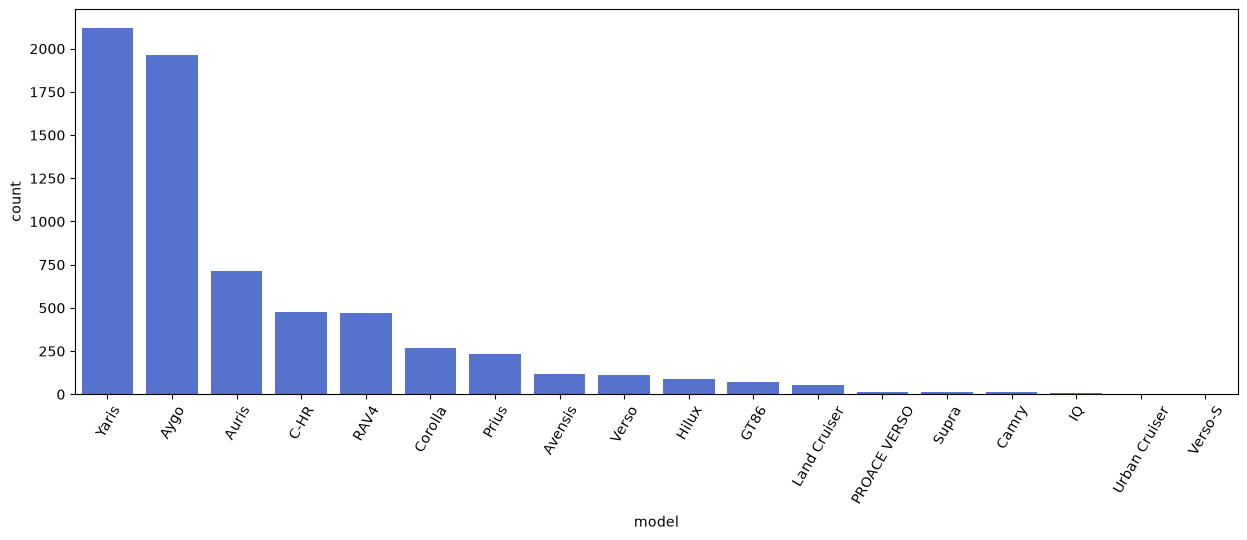

In [24]:
fig = plt.figure(figsize=(15, 5))
sns.countplot(data=df, x='model', order=df['model'].value_counts().index, color='royalblue')
plt.xticks(rotation=60)

# ukuran mesin

In [26]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax').reset_index()
engine = engine.rename(columns={'tax':'count'})

<Axes: xlabel='engineSize', ylabel='count'>

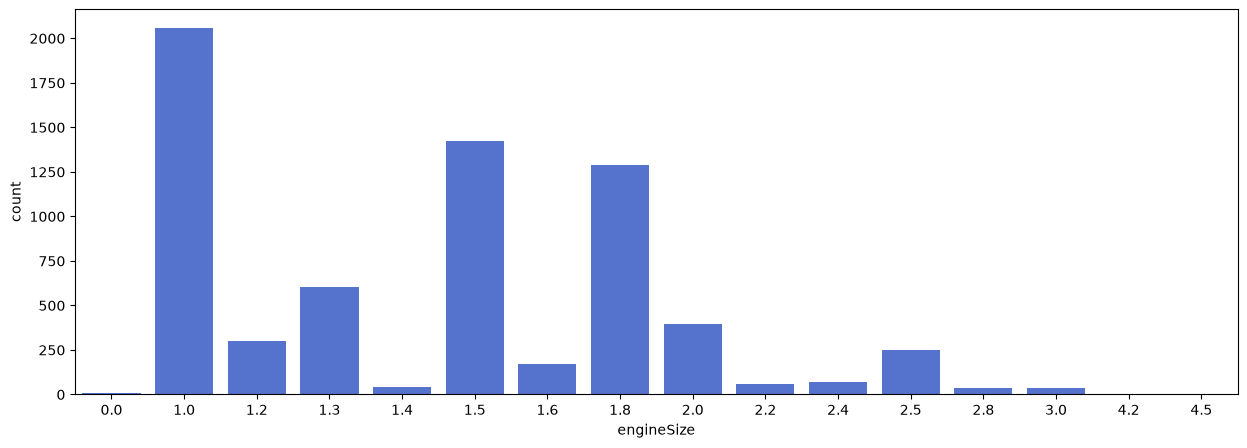

In [28]:
plt.figure(figsize=(15,5))
sns.barplot(x=engine['engineSize'], y=engine['count'],color='royalblue')

# distribusi mileage

<Figure size 1500x500 with 0 Axes>

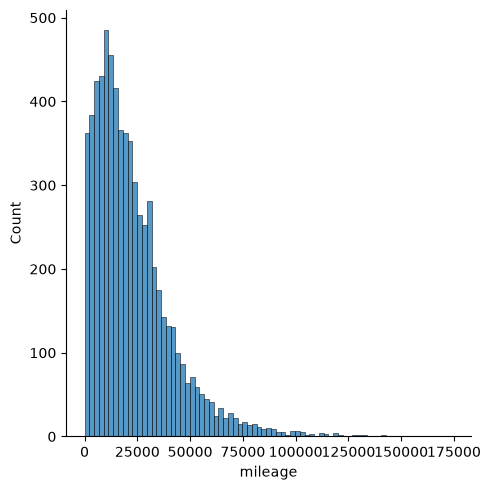

In [29]:
plt.figure(figsize=(15,5))
sns.displot(df['mileage'])

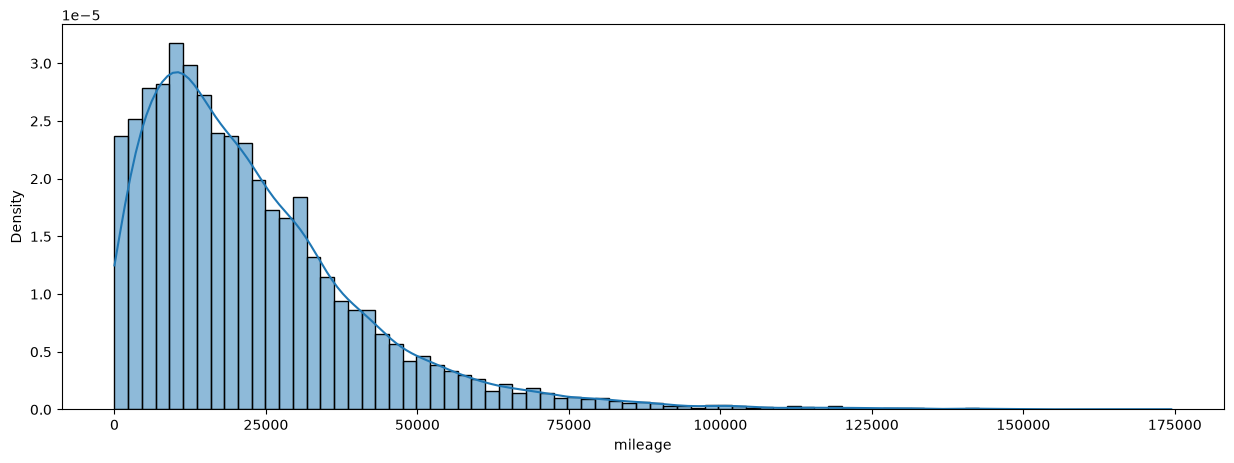

In [30]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

plt.figure(figsize=(15, 5))
sns.histplot(data=df, x='mileage', stat='density', kde=True)
plt.xlabel('mileage')
plt.ylabel('Density')
plt.show()

# distribusi harga mobil

<Axes: xlabel='price', ylabel='Density'>

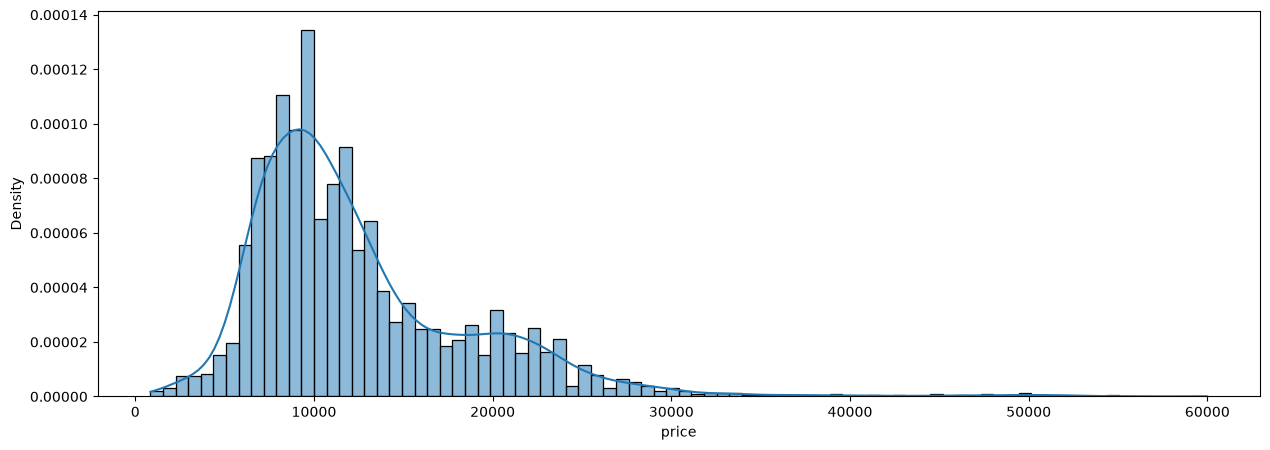

In [33]:
plt.figure(figsize=(15, 5))
sns.histplot(data=df, x='price', stat='density', kde=True)

# seleksi fitur

In [35]:
features = ['year','mileage','tax','mpg','engineSize']
x = df[features]
y = df['price']
x.shape, y.shape

((6738, 5), (6738,))

# split data training dan data testing

In [38]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,random_state=70)

ModuleNotFoundError: No module named 'sklearn'

In [39]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.4 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/8.4 MB 1.4 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.4 MB 1.4 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.4 MB 1.4 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.4 MB 1.1 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.4 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.6/8.4 MB 852.3 kB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.4 MB 852.3 kB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.4 MB 852.3 kB/s eta 0:00:08
   -------- ------------------------------- 1.8/8.4 MB 704.5 kB/s eta 0:00:10
   -------- ------------------------------- 1.8/8.4 MB 704.5 kB/s eta 0:00:10
   ---------- --


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, Y, random_state=70)
y_test.shape[0]

1685

# membuat model regresi linier

In [45]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)
pred = lr.predict(x_test)

In [46]:
score = lr.score(x_test, y_test)
print('akurasi model regresi linier = ', score)

akurasi model regresi linier =  0.7678983314475204


# membuat inputan model regresi linier

In [48]:
#year=2019, mileage=5000, tax=145, mpg=30.2, engineSize=2
input_data = np.array([[2019,5000,145,30.2,2]])

prediction = lr.predict(input_data)
print('Estimasi harga mobil dalam EUR :', prediction)

Estimasi harga mobil dalam EUR : [21208.50538579]


c:\Users\Windows\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# save model

In [49]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(lr,open(filename,'wb'))

In [31]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
